In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

from ics26_experiments import RESULTS_DIR

In [ ]:
ICS26_DIR = RESULTS_DIR / "ics26"
for d in ICS26_DIR.iterdir():
    print(d.name)

adaptive_clustering_global_vs_local
adaptive_clustering_global_vs_n_init_clusters
adaptive_clustering_global_local_vs_min_pts_per_cluster
ellipsoidal_knn_containment
rosenbrock_convergence_no_containment
shifted_gaussians_no_q_shrink_global_error_scaling
shifted_gaussians_with_q_shrink_global_error_scaling
shifted_gaussians_with_identity_global_error_scaling


In [ ]:
# Publication-Quality Plot Settings
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.figsize": (6.5, 4.5),
        "figure.dpi": 100,
        "savefig.dpi": 300,
        "lines.linewidth": 1.5,
        "lines.markersize": 5,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
    }
)
PALETTE = "deep"
COLORS = sns.color_palette(PALETTE)

# Shifted Gaussians (No Q Shrink, Global Error Scaling)

In [ ]:
shifted_gaussians_dir = ICS26_DIR / "shifted_gaussians_no_q_shrink_global_error_scaling"
csv_path = shifted_gaussians_dir / "summary.csv"

df_sg = pd.read_csv(csv_path)

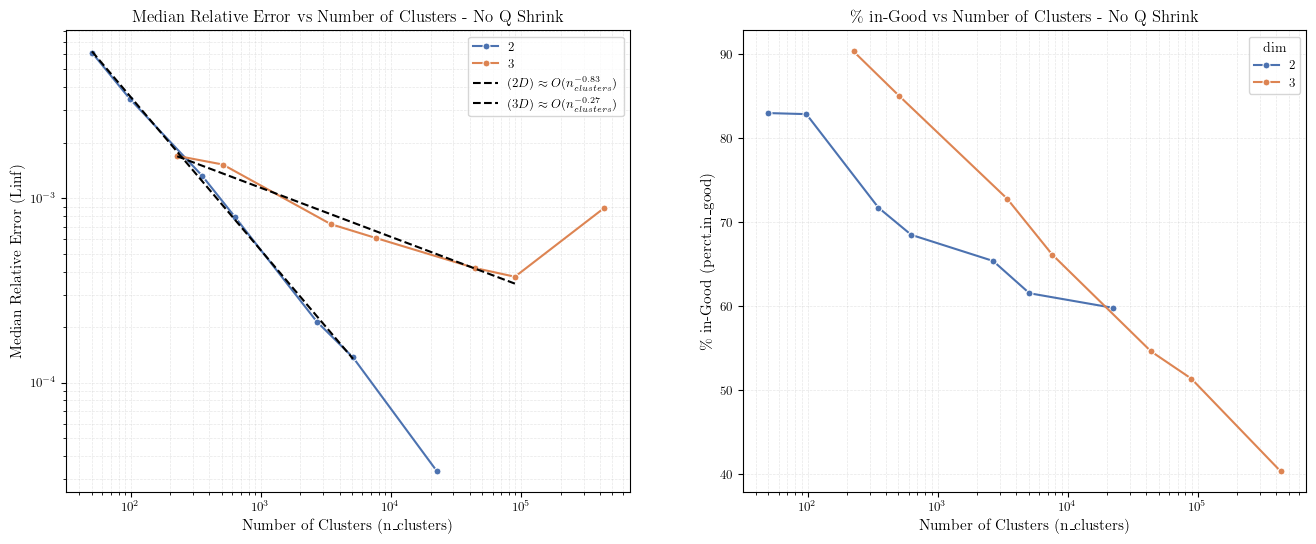

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_sg,
    x="n_clusters",
    y="median_rel_error_linf",
    hue="dim",
    marker="o",
    palette=PALETTE,
)
# Fit linear regression lines (in log-log space) for each dimension
for dim in df_sg["dim"].unique():
    subset = df_sg[df_sg["dim"] == dim]
    X = np.log(subset["n_clusters"].values).reshape(-1, 1)
    y = np.log(subset["median_rel_error_linf"].values)
    # Drop the last point to avoid outlier influence
    X = X[:-1]
    y = y[:-1]
    model = LinearRegression()
    model.fit(X, y)
    x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    y_fit = model.predict(x_fit)
    label = rf"$({dim}D) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
    plt.plot(np.exp(x_fit), np.exp(y_fit), linestyle="--", color="k", label=label)
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel("Median Relative Error (Linf)")
plt.title("Median Relative Error vs Number of Clusters - No Q Shrink")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_sg,
    x="n_clusters",
    y="perct_in_good",
    hue="dim",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel(r"$\%$ in-Good (perct_in_good)")
plt.title(r"$\%$ in-Good vs Number of Clusters - No Q Shrink")
plt.grid(True, which="both", ls="--", lw=0.5)

# Shifted Gaussians (With Q Shrink, Global Error Scaling)

In [ ]:
shifted_gaussians_dir = (
    ICS26_DIR / "shifted_gaussians_with_q_shrink_global_error_scaling"
)
csv_path = shifted_gaussians_dir / "summary.csv"

df_wsg = pd.read_csv(csv_path)

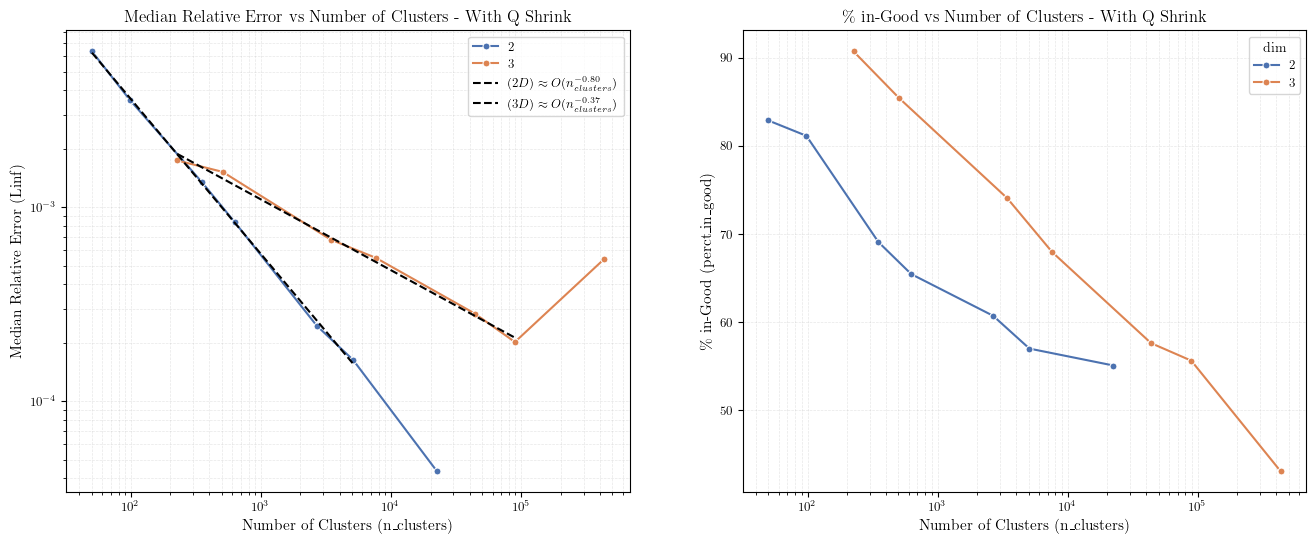

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_wsg,
    x="n_clusters",
    y="median_rel_error_linf",
    hue="dim",
    marker="o",
    palette=PALETTE,
)
# Fit linear regression lines (in log-log space) for each dimension
for dim in df_wsg["dim"].unique():
    subset = df_wsg[df_wsg["dim"] == dim]
    X = np.log(subset["n_clusters"].values).reshape(-1, 1)
    y = np.log(subset["median_rel_error_linf"].values)
    # Drop the last point to avoid outlier influence
    X = X[:-1]
    y = y[:-1]
    model = LinearRegression()
    model.fit(X, y)
    x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    y_fit = model.predict(x_fit)
    label = rf"$({dim}D) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
    plt.plot(np.exp(x_fit), np.exp(y_fit), linestyle="--", color="k", label=label)
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel("Median Relative Error (Linf)")
plt.title("Median Relative Error vs Number of Clusters - With Q Shrink")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_wsg,
    x="n_clusters",
    y="perct_in_good",
    hue="dim",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel(r"$\%$ in-Good (perct_in_good)")
plt.title(r"$\%$ in-Good vs Number of Clusters - With Q Shrink")
plt.grid(True, which="both", ls="--", lw=0.5)